In [3]:
from google.colab import drive
import os

drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/Proyecto_señales')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


✅ Procesado secret1.wav -> Guardados encoded_1.wav y FFT_key_1.csv


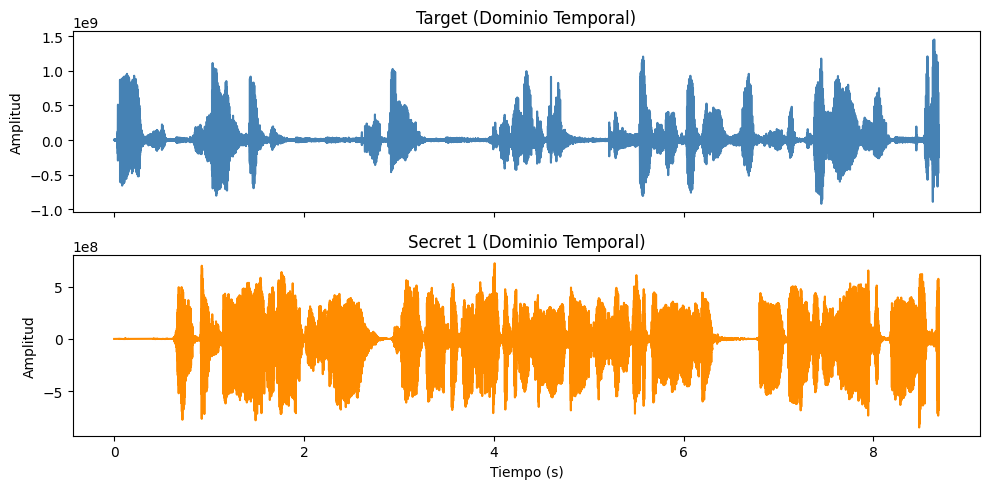

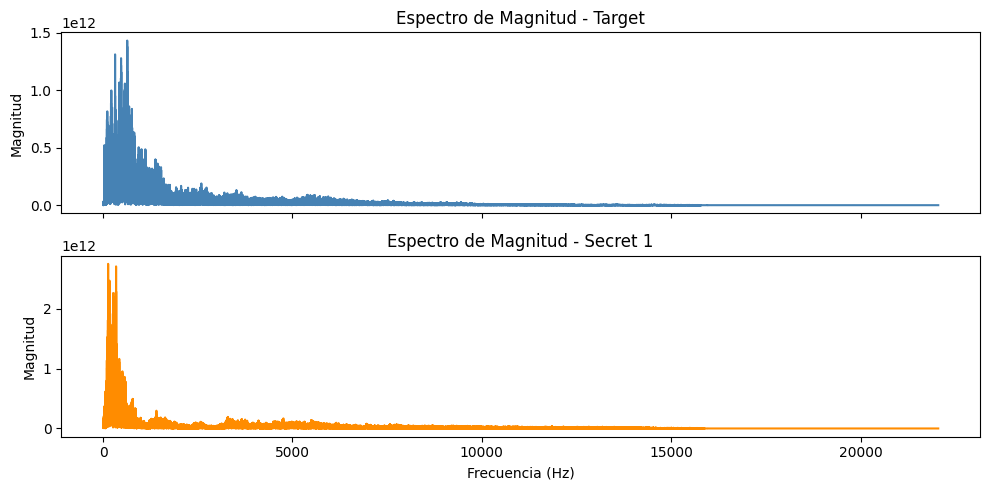

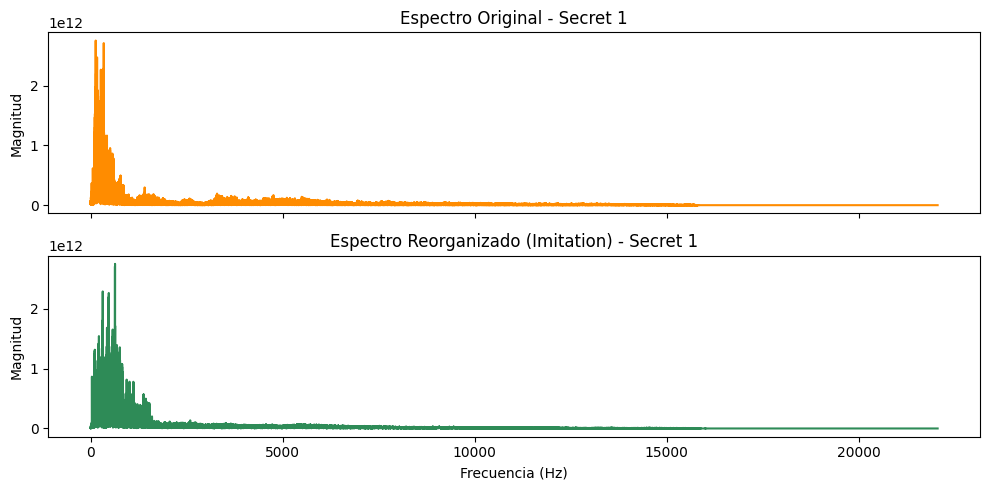

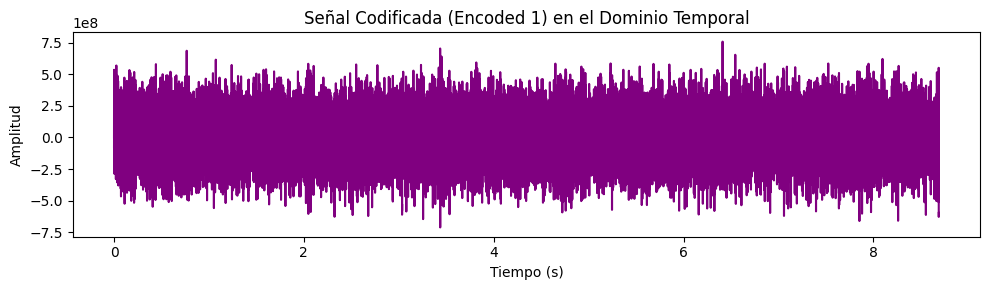

🔊 Escucha el audio codificado (Encoded 1):


✅ Procesado secret2.wav -> Guardados encoded_2.wav y FFT_key_2.csv
✅ Procesado secret3.wav -> Guardados encoded_3.wav y FFT_key_3.csv
✅ Procesado secret4.wav -> Guardados encoded_4.wav y FFT_key_4.csv
✅ Procesado secret5.wav -> Guardados encoded_5.wav y FFT_key_5.csv


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read, write
from scipy.fft import rfft, irfft, rfftfreq
from IPython.display import Audio, display

# 1. CARGAR EL AUDIO DE REFERENCIA
fs_target, target = read('target.wav')
target = target.astype(float)

if target.ndim > 1:
    target = target[:, 0]

N = len(target)
T = rfft(target)
frecuencias = rfftfreq(N, d=1/fs_target)

archivos_secretos = [
    'secret1.wav',
    'secret2.wav',
    'secret3.wav',
    'secret4.wav',
    'secret5.wav'
]

# 2. PROCESAR LOS 5 MENSAJES SECRETOS
for i, nombre_archivo in enumerate(archivos_secretos, start=1):
    fs_sec, secret = read(nombre_archivo)
    secret = secret.astype(float)

    if secret.ndim > 1:
        secret = secret[:, 0]

    assert fs_target == fs_sec, f"Error: {nombre_archivo} tiene diferente fs."
    assert N == len(secret), f"Error: {nombre_archivo} tiene diferente longitud."

    S = rfft(secret)

    # 3. DEFINIR POSICIONES PERMUTABLES (Dejando fijos DC y Nyquist)
    if N % 2 == 0:
        P = np.arange(1, len(S) - 1)
    else:
        P = np.arange(1, len(S))

    # 4. PERMUTACIÓN ESPECTRAL Y CREACIÓN DE LA CLAVE
    I1 = np.argsort(np.abs(S[P]))
    I2 = np.argsort(np.abs(T[P]))

    K = np.arange(len(S))
    K[P[I2]] = P[I1]

    E = S[K]

    # 5. RECONSTRUIR AUDIO CODIFICADO EN EL TIEMPO
    encoded = irfft(E, n=N)

    # 6. GUARDAR AUDIO CODIFICADO Y CLAVE EN TU CARPETA
    nombre_encoded = f'encoded_{i}.wav'
    nombre_clave = f'FFT_key_{i}.csv'

    write(nombre_encoded, fs_target, encoded.astype(np.float32))
    np.savetxt(nombre_clave, K, fmt='%d', header='key', comments='')

    print(f"✅ Procesado {nombre_archivo} -> Guardados {nombre_encoded} y {nombre_clave}")

    # 7. GENERAR LAS 4 GRÁFICAS DE ANÁLISIS (SOLO PARA EL PRIMER SECRETO)
    if i == 1:
        tiempo = np.arange(N) / fs_target

        # Gráfica 1: Señales originales en el dominio temporal
        fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
        axs[0].plot(tiempo, target, color='steelblue')
        axs[0].set_title('Target (Dominio Temporal)')
        axs[0].set_ylabel('Amplitud')
        axs[1].plot(tiempo, secret, color='darkorange')
        axs[1].set_title('Secret 1 (Dominio Temporal)')
        axs[1].set_xlabel('Tiempo (s)')
        axs[1].set_ylabel('Amplitud')
        plt.tight_layout()
        plt.savefig('Grafica_tiempo.png', dpi=300)
        plt.show()

        # Gráfica 2: Espectros de magnitud
        fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
        axs[0].plot(frecuencias, np.abs(T), color='steelblue')
        axs[0].set_title('Espectro de Magnitud - Target')
        axs[0].set_ylabel('Magnitud')
        axs[1].plot(frecuencias, np.abs(S), color='darkorange')
        axs[1].set_title('Espectro de Magnitud - Secret 1')
        axs[1].set_xlabel('Frecuencia (Hz)')
        axs[1].set_ylabel('Magnitud')
        plt.tight_layout()
        plt.savefig('Grafica_espectro.png', dpi=300)
        plt.show()

        # Gráfica 3: Espectro original vs reorganizado
        fig, axs = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
        axs[0].plot(frecuencias, np.abs(S), color='darkorange')
        axs[0].set_title('Espectro Original - Secret 1')
        axs[0].set_ylabel('Magnitud')
        axs[1].plot(frecuencias, np.abs(E), color='seagreen')
        axs[1].set_title('Espectro Reorganizado (Imitation) - Secret 1')
        axs[1].set_xlabel('Frecuencia (Hz)')
        axs[1].set_ylabel('Magnitud')
        plt.tight_layout()
        plt.savefig('Grafica_espectro_ordenado.png', dpi=300)
        plt.show()

        # Gráfica 4: Señal codificada en el dominio temporal
        plt.figure(figsize=(10, 3))
        plt.plot(tiempo, encoded, color='purple')
        plt.title('Señal Codificada (Encoded 1) en el Dominio Temporal')
        plt.xlabel('Tiempo (s)')
        plt.ylabel('Amplitud')
        plt.tight_layout()
        plt.savefig('Grafica_encoded.png', dpi=300)
        plt.show()

        print("🔊 Escucha el audio codificado (Encoded 1):")
        display(Audio(encoded, rate=fs_target))
